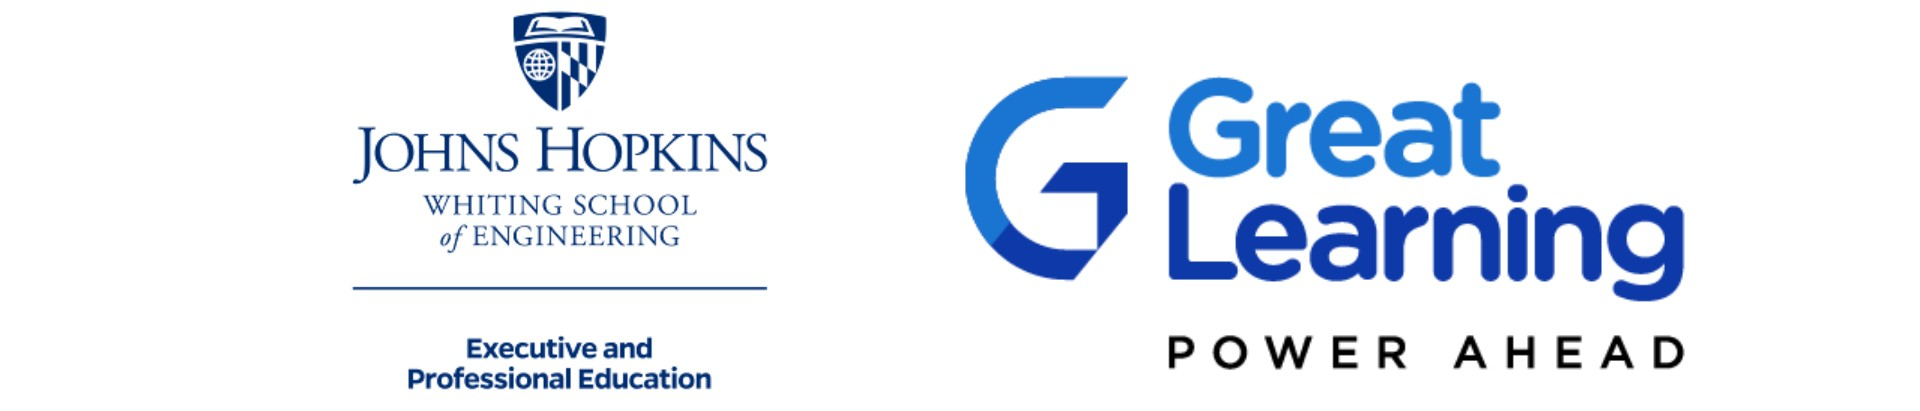

<center><font size=10>Planning and Reasoning Mechanisms</center></font>
<center><font size=6>LexAgent for Rental Law Reasoning</center></font>


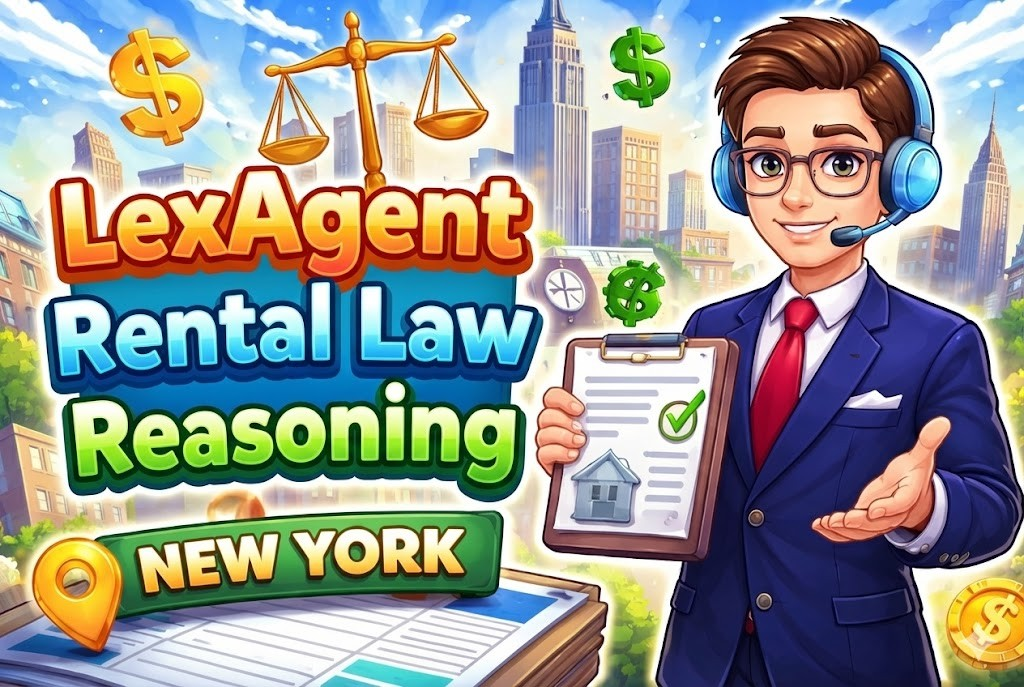

## Problem Scenario

Rental laws are complex, jurisdiction-specific, and frequently updated. Renters and landlords often struggle to understand their rights and obligations due to dense legal language, fragmented regulations, and limited access to legal expertise. Reviewing rental agreements, interpreting housing policies, and learning from prior court cases is time-consuming and costly, leading to non-compliance, disputes, and legal risk.

A scalable, intelligent solution is needed to simplify rental law interpretation and provide reliable, jurisdiction-aware legal guidance.


## Proposed Solution
**LexAgent** is a legal intelligence system that analyzes rental laws, reviews agreements, and reasons over historical case outcomes across jurisdictions.

### Core Capabilities
- Look up and interpret rental policies and regulations
- Analyze relevant past housing cases and their outcomes
- Review and rewrite rental agreement clauses for compliance
- Explain legal rights and obligations in plain language
- Evaluate agent performance with task-completion checks and LLM-as-a-Judge


---

## Example: New York Rent Legal Agent

As a jurisdiction-specific implementation, the New York Rent Legal Agent applies this framework to New York State and NYC housing laws.

**Example Use Cases**
- Validate lease clauses against NY rental regulations
- Analyze outcomes of prior NY housing court cases
- Rewrite non-compliant lease sections
- Explain tenant and landlord rights under NY law

---

## **Note**
- The content in this notebook and datasets (PDFs) is provided as part of a demonstration scenario.
- It is intended for learning purposes and does not represent an official document, policy, or formal recommendation from any source, nor does it constitute legal advice.


## 1. Setup — Install Dependencies

All version pins below were verified together as a working set: the MCP server (streamable HTTP), the `langchain-mcp-adapters` async client, LangGraph, and Chroma. Two pins matter most:

- `mcp[cli]==1.12.4` — streamable-HTTP transport requires `mcp >= 1.8`; older pins (e.g. 1.4.x) crash at server startup. The `[cli]` extra bundles the `fastmcp` development CLI; the `FastMCP` class used by the server is in the base package.
- `langchain-mcp-adapters==0.1.9` — in the 0.1.x line `get_tools()` is **async** (`await client.get_tools()`). Leaving this unpinned is dangerous: in older versions the same method is synchronous and the `await` fails.


> **Note on install output:** During installation you may see dependency conflict warnings highlighted in red. These are pre-existing conflicts with base-environment packages not used by this notebook. The install completes successfully and the warnings can be safely ignored.

In [ ]:
# !pip install -q \
#     langchain==0.3.27 \
#     langchain-openai==0.3.9 \
#     langchain-community==0.3.27 \
#     langgraph==0.3.34 \
#     langchain-mcp-adapters==0.1.9 \
#     "mcp[cli]"==1.12.4 \
#     langchain-chroma==0.2.4 \
#     chromadb==1.0.20 \
#     pypdf==5.4.0 \
#     tavily-python==0.7.12

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.2/148.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.1/160.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.8/19.8 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.3/302.3 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 461.3/461.3 kB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/4

### Imports

In [2]:
import os
import re
import ast
import json
import time
import socket
import operator
import subprocess
import sys
from typing import List, Annotated, TypedDict, Literal

# LangChain / LangGraph core
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, ToolMessage
from langchain_core.prompts import PromptTemplate
from langchain_core.tools.render import render_text_description_and_args
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_core.agents import AgentFinish
# Legacy LangChain class; used here for its minimal Thought/Action/Final Answer text-parsing contract.
from langchain_classic.agents.output_parsers import ReActSingleInputOutputParser
from langgraph.graph import StateGraph, END

# MCP client (server-side imports live inside legal_mcp_server.py)
from langchain_mcp_adapters.client import MultiServerMCPClient

## 2. Load Configuration and Initialize the Language Model

Reads API credentials from `config.json` (upload it to the Colab working directory before running). The same file is read independently by the MCP server process in Section 5, so both processes share one credential source.


In [3]:
# Upload config.json to the Colab working directory before running this cell.
# Expected keys (exactly as read below): API_KEY, OPENAI_API_BASE, TAVILY_API_KEY
with open("../../../config.json", "r") as f:
    config = json.load(f)

os.environ["OPENAI_API_KEY"] = config["API_KEY"]
os.environ["OPENAI_API_BASE"] = config["OPENAI_API_BASE"]
os.environ["TAVILY_API_KEY"] = config["TAVILY_API_KEY"]

# Deterministic settings for a reproducible classroom demo
llm = ChatOpenAI(model_name="gpt-4o-mini", temperature=0.0)
embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")

print("LLM and embedding model initialized.")

LLM and embedding model initialized.


## 3. RAG Vector Store Initialization

Policy and case-law PDFs are chunked and embedded into **in-memory** Chroma collections using `Chroma.from_documents()`.

The notebook builds these collections here purely to verify that the PDFs load and embed correctly. The MCP server process (Section 5) builds its **own** in-memory copies from the same PDFs at startup — the two processes share no disk state and no Chroma directory.

In [4]:
# Upload both PDFs to the Colab working directory (or edit these paths).
POLICY_PDF = "tenants_rights.pdf"     # Reference document on tenant rights
CASES_PDF = "previous_cases.pdf"      # Dummy prior-case documents for the demo

for pdf in (POLICY_PDF, CASES_PDF):
    if not os.path.exists(pdf):
        raise FileNotFoundError(
            f"'{pdf}' not found. Upload it to the working directory "
            "or update the path variables above."
        )

In [5]:
def build_vectorstore(pdf_path: str, collection_name: str) -> Chroma:
    """
    Load a PDF, split it into overlapping chunks, and embed the chunks
    into an in-memory Chroma collection for local verification.
    """
    documents = PyPDFLoader(pdf_path).load()

    # Normalize PDF extraction artifacts (pypdf often emits one word per line
    # with stray blank lines). Collapsing whitespace keeps the chunks clean,
    # improves embedding quality, and makes tool observations readable.
    for doc in documents:
        doc.page_content = re.sub(r"\s+", " ", doc.page_content).strip()

    splits = RecursiveCharacterTextSplitter(
        chunk_size=1000,     # ~1 page-section per chunk
        chunk_overlap=200,   # overlap preserves cross-boundary context
    ).split_documents(documents)

    vectorstore = Chroma.from_documents(
        documents=splits,
        embedding=embedding_model,
        collection_name=collection_name,
    )
    print(f"'{collection_name}': {len(documents)} pages -> {len(splits)} chunks embedded")
    return vectorstore


policy_vectorstore = build_vectorstore(POLICY_PDF, "legal_policies")
cases_vectorstore = build_vectorstore(CASES_PDF, "legal_cases")

'legal_policies': 36 pages -> 123 chunks embedded
'legal_cases': 2 pages -> 7 chunks embedded


## 4. MCP Server — Write the Tool Server File

All five tools are wrapped as MCP tools with `FastMCP` and served over **streamable HTTP**

Two implementation details worth noticing:

- `host` and `port` are passed to the **`FastMCP(...)` constructor**, not to `mcp.run()` — passing them to `run()` raises a `TypeError` on current `mcp` versions.
- The server builds **its own in-memory Chroma collections** from the same PDFs at startup — no shared disk directory is needed.


In [8]:
%%writefile legal_mcp_server.py
"""
LexAgent MCP tool server.

Runs as a standalone process and exposes five tools over MCP
(streamable HTTP). The notebook connects to it as an MCP client,
so every tool call in the agent is a genuine client -> server round trip.
"""

import os
import json
import re

from mcp.server.fastmcp import FastMCP
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from tavily import TavilyClient

# --- Credentials: same config.json the notebook uses ---
with open("../../../config.json", "r") as f:
    config = json.load(f)

os.environ["OPENAI_API_KEY"] = config["API_KEY"]
os.environ["OPENAI_API_BASE"] = config["OPENAI_API_BASE"]

llm = ChatOpenAI(model_name="gpt-4o-mini", temperature=0.0)
embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")
tavily_client = TavilyClient(api_key=config["TAVILY_API_KEY"])

# --- Vector stores: built in-memory from PDFs at server startup ---
def _build_store(pdf_path: str, collection_name: str) -> Chroma:
    docs = PyPDFLoader(pdf_path).load()
    for doc in docs:
        doc.page_content = re.sub(r"\s+", " ", doc.page_content).strip()
    splits = RecursiveCharacterTextSplitter(
        chunk_size=1000, chunk_overlap=200
    ).split_documents(docs)
    return Chroma.from_documents(
        documents=splits,
        embedding=embedding_model,
        collection_name=collection_name,
    )

policy_vectorstore = _build_store("tenants_rights.pdf", "legal_policies")
cases_vectorstore  = _build_store("previous_cases.pdf",  "legal_cases")

# host/port belong in the constructor (server settings), NOT in mcp.run()
mcp = FastMCP("lexagent-tools", host="127.0.0.1", port=8765)


# ---------------------------------------------------------------
# Tool 1: parse_query — deterministic scope check + intent tagging
# ---------------------------------------------------------------
@mcp.tool()
def parse_query(query: str) -> str:
    """
    Validate that a query is about tenant/landlord (housing) law and tag
    its intent, property type, tenancy type, and key legal issues.
    Rejects out-of-scope queries. Rule-based by design: deterministic,
    cheap, and easy to audit. Jurisdiction is fixed to New York for this
    demo implementation.
    """
    q = query.lower()

    tenant_keywords = ["tenant", "landlord", "lease", "rent", "eviction", "apartment",
                       "security deposit", "repairs", "housing", "unit", "renter"]
    if not any(k in q for k in tenant_keywords):
        return ("OUT_OF_SCOPE:\n"
                "This agent handles tenant and landlord (housing) law only.\n"
                "Please ask a tenant-related question.")

    if "evict" in q:
        intent = "Eviction Defense / Eviction Process"
    elif "rent increase" in q or "raise rent" in q:
        intent = "Rent Control / Rent Increase Legality"
    elif "security deposit" in q:
        intent = "Security Deposit Dispute"
    elif "repair" in q or "habitability" in q:
        intent = "Repairs & Habitability Rights"
    elif "lease" in q:
        intent = "Lease Review / Interpretation"
    elif "retaliation" in q:
        intent = "Tenant Retaliation Claim"
    elif "discrimination" in q:
        intent = "Housing Discrimination"
    else:
        intent = "General Tenant Rights Inquiry"

    property_type = "Unspecified Residential Unit"
    if "apartment" in q:
        property_type = "Apartment"
    elif "house" in q:
        property_type = "Single-family Home"
    elif "condo" in q:
        property_type = "Condominium"

    tenancy_type = "Unspecified"
    if "month-to-month" in q:
        tenancy_type = "Month-to-Month"
    elif (
        "fixed term" in q or "1 year" in q or "1-year" in q
        or "2-year" in q or "3-year" in q or "4-year" in q or "5-year" in q
        or "two-year" in q or "three-year" in q or "four-year" in q or "five-year" in q
        or "2 year" in q or "3 year" in q or "4 year" in q or "5 year" in q
        or "two year" in q or "three year" in q or "four year" in q or "five year" in q
    ):
        tenancy_type = "Fixed-Term Lease"

    legal_issues = []
    if "notice" in q:
        legal_issues.append("Notice requirements")
    if "deposit" in q:
        legal_issues.append("Security deposit handling")
    if "repair" in q:
        legal_issues.append("Implied warranty of habitability")
    if "lockout" in q or "change the locks" in q or "changing locks" in q:
        legal_issues.append("Illegal lockout / self-help eviction")
    if "sublet" in q or "subletting" in q or "airbnb" in q:
        legal_issues.append("Unauthorized subletting")
    if "rent" in q:
        legal_issues.append("Rent payment obligations")
    if not legal_issues:
        legal_issues.append("General tenant protections")

    return f"""Parsed Tenant Law Query
-----------------------
Scope Validation: Tenant / Landlord Law CONFIRMED
User Intent: {intent}
Jurisdiction: New York, US (fixed for this demo)
Property Type: {property_type}
Tenancy Type: {tenancy_type}
Key Legal Issues:
- """ + "\n- ".join(legal_issues)


# ---------------------------------------------------------------
# Tool 2: policy_search_tool — RAG over the policy knowledge base
# ---------------------------------------------------------------
@mcp.tool()
def policy_search_tool(query: str) -> str:
    """
    Semantic search over the local tenant-rights policy knowledge base,
    which covers foundational New York housing statutes, established
    regulations, and tenant protections compiled before 2023. Returns
    the top relevant policy excerpts. For recently enacted laws or
    regulatory changes from 2023 onwards, supplement with
    tavily_web_search_tool if this tool returns no directly relevant result.
    """
    docs = policy_vectorstore.similarity_search(query, k=2)
    if not docs:
        return "No relevant legal policy found in the knowledge base."

    return "\n\n".join(
        f"Policy Excerpt {i}:\n{doc.page_content}" for i, doc in enumerate(docs, 1)
    )


# ---------------------------------------------------------------
# Tool 3: cases_search_tool — RAG over prior case documents
# ---------------------------------------------------------------
@mcp.tool()
def cases_search_tool(query: str) -> str:
    """
    Semantic search over a curated collection of prior New York
    housing-court case documents (cases decided before 2023).
    Returns the top relevant case precedents. For court decisions
    from 2023 onwards or recently argued cases, supplement with
    tavily_web_search_tool if this tool returns no relevant result.
    """
    docs = cases_vectorstore.similarity_search(query, k=3)
    if not docs:
        return "No relevant legal cases found in the knowledge base."

    return "\n\n".join(
        f"Case Precedent {i}:\n{doc.page_content}" for i, doc in enumerate(docs, 1)
    )


# ---------------------------------------------------------------
# Tool 4: tavily_web_search_tool — live web search for recent cases
# ---------------------------------------------------------------
@mcp.tool()
def tavily_web_search_tool(query: str) -> str:
    """
    Search the live web for recent New York rent-related legal
    developments — newly enacted statutes, court rulings from 2023
    onwards, and current regulatory changes — that are not yet in
    the local knowledge base. Use this tool when local retrieval
    (policy_search_tool or cases_search_tool) returns no result
    that directly addresses the user's question about current or
    recent law.
    """
    response = tavily_client.search(query=query, max_results=5, search_depth="advanced")
    results = response.get("results", [])
    if not results:
        return "No recent New York rent-related legal results found."

    return "\n\n".join(
        f"Result {i}:\n{r.get('content', 'No content')}\nSource: {r.get('url', 'n/a')}"
        for i, r in enumerate(results, 1)
    )


# ---------------------------------------------------------------
# Tool 5: rewrite_legal_clause — LLM rewrite grounded in evidence
# ---------------------------------------------------------------
@mcp.tool()
def rewrite_legal_clause(
    original_clause: str,
    parsed_claim: str,
    policy_excerpts: str,
    case_law_excerpts: str,
) -> str:
    """
    Rewrite a lease clause (or set of clauses) for legal compliance,
    grounded in previously retrieved evidence. Call this AFTER
    parse_query, policy_search_tool, and cases_search_tool so their
    outputs can be passed in as arguments.
    """
    prompt = f"""You are a legal drafting assistant.

Rewrite the ORIGINAL CLAUSE so that it fully complies with the applicable
law described in the POLICY EXCERPTS and CASE LAW below, while remaining
as landlord-protective as legally permitted. Base every change ONLY on
the provided materials — do not invent statutes or citations.

PARSED CLAIM CONTEXT:
{parsed_claim}

POLICY EXCERPTS:
{policy_excerpts}

CASE LAW EXCERPTS:
{case_law_excerpts}

ORIGINAL CLAUSE:
{original_clause}

Return: (1) the rewritten clause(s), then (2) a brief bullet list of what
was changed and why."""
    response = llm.invoke(prompt)
    return response.content


# ---------------------------------------------------------------
# Run server over streamable HTTP (endpoint: http://127.0.0.1:8765/mcp)
# ---------------------------------------------------------------
if __name__ == "__main__":
    mcp.run(transport="streamable-http")

Overwriting legal_mcp_server.py


## 5. Launch the MCP Server as a Background Process

The launch cell fails fast on a crash (missing `config.json`, bad pins, port in use) and then polls the port until the server is actually accepting connections — `time.sleep()` alone is a race condition.

Server output is redirected to **`mcp_server.log`** rather than a pipe: an undrained `subprocess.PIPE` buffer can fill up and silently block a long-running server, and the log file doubles as a diagnostic if a tool call ever misbehaves mid-session.

---

> **NOTE** : If failed, try re-executing the below cell to start the MCP server

In [9]:
def wait_for_port(host: str, port: int, timeout: float = 20.0) -> bool:
    """Poll a TCP port until it accepts connections (server is up) or timeout."""
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False


# Redirect server output to a log file. PIPE buffers are never drained here,
# so a chatty server could eventually block on a full pipe; a file cannot.
server_log = open("mcp_server.log", "w")

mcp_server_process = subprocess.Popen(
    [sys.executable, "legal_mcp_server.py"],
    stdout=server_log,
    stderr=subprocess.STDOUT,
)

time.sleep(2)  # brief pause so an immediate crash is observable

# Fail fast if the server crashed on startup.
if mcp_server_process.poll() is not None:
    server_log.close()
    with open("mcp_server.log") as f:
        raise RuntimeError(
            "legal_mcp_server.py exited immediately.\nLOG:\n" + f.read()
        )

# Wait until the HTTP endpoint is actually reachable.
if not wait_for_port("127.0.0.1", 8765):
    mcp_server_process.terminate()
    server_log.close()
    raise RuntimeError(
        "MCP server did not start listening on port 8765 within 20s. "
        "See mcp_server.log for details."
    )

print(f"MCP server is up on http://127.0.0.1:8765/mcp "
      f"(PID {mcp_server_process.pid}) — logs: mcp_server.log")


MCP server is up on http://127.0.0.1:8765/mcp (PID 8101) — logs: mcp_server.log


## 6. Connect the MCP Client and Load Tools

`get_tools()` is **async** in `langchain-mcp-adapters` 0.1.x, and Colab supports top-level `await`.


In [10]:
mcp_client = MultiServerMCPClient(
    {
        "lexagent_tools": {
            "url": "http://127.0.0.1:8765/mcp",
            "transport": "streamable_http",
        },
    }
)

EXPECTED_TOOLS = {
    "parse_query",
    "policy_search_tool",
    "cases_search_tool",
    "tavily_web_search_tool",
    "rewrite_legal_clause",
}

mcp_tools = await mcp_client.get_tools()
loaded = {t.name for t in mcp_tools}

# Deliberately strict: a partial/empty tool set must stop the notebook.
if loaded != EXPECTED_TOOLS:
    raise RuntimeError(
        f"Expected tools {sorted(EXPECTED_TOOLS)} but loaded {sorted(loaded)}. "
        "Check that the MCP server started cleanly (Section 5)."
    )

print(f"✅ Loaded {len(mcp_tools)} MCP tools: {sorted(loaded)}")

✅ Loaded 5 MCP tools: ['cases_search_tool', 'parse_query', 'policy_search_tool', 'rewrite_legal_clause', 'tavily_web_search_tool']


## 7. ReAct-Based Legal Reasoning Agent Workflow

The agent's tool set is served entirely via MCP. The ReAct loop is implemented explicitly (rather than with a prebuilt agent) so the mechanics are visible for teaching. Four design decisions keep it honest:

1. **Stop sequence on `"Observation:"`** — the model is physically prevented from generating (hallucinating) its own observations. Real observations come only from MCP tool calls.
2. **Tool schemas + Explicit Action Input examples in the prompt** — `render_text_description_and_args` exposes each tool's argument schema, and the prompt shows exactly what a valid Action Input looks like, so the model passes plain values instead of echoing the schema back (e.g. `{'title': ..., 'type': ...}`).
3. **Full scratchpad** — every prior Thought/Action/Observation is replayed each turn, so later steps (like clause rewriting) can use earlier retrieved evidence.
4. **Visible Fail/Error handling** — an unparseable Action Input or a malformed ReAct turn is surfaced as an explicit *system note*, never disguised as a tool observation, and the agent gets a bounded chance to self-correct within the step cap.


### 7.1 Agent State and ReAct Prompt

In [11]:
class AgentState(TypedDict):
    """LangGraph state: the running message transcript + a step counter."""
    messages: Annotated[List[BaseMessage], operator.add]
    step_count: int


MAX_AGENT_STEPS = 8  # hard cap on reasoning turns to prevent infinite loops

# Tool names + argument schemas are rendered into the prompt so the model
# knows exactly how to call each tool.
TOOLS_DESC = render_text_description_and_args(mcp_tools)
tool_map = {t.name: t for t in mcp_tools}

REACT_TEMPLATE = """You are LexAgent, a legal reasoning assistant for New York tenant/landlord (housing) law. You answer using the ReAct framework: reason step by step, call tools to gather evidence, then give a precise final answer grounded entirely in what those tools return. Do not assert statutes, case names, or legal rules from your own training knowledge — always retrieve evidence first.

You have access to the following tools:
{tools}

Rules:
- ALWAYS call parse_query first, passing the user's question verbatim, to validate and structure the query.
- Use policy_search_tool for statutes/regulations and cases_search_tool for prior cases.
- Use tavily_web_search_tool for recent developments — newly enacted statutes, court rulings from 2023 onwards, or current regulatory changes — that the local knowledge base (which covers foundational statutes and historical cases) may not yet contain. If local retrieval returns results that do not directly address the user's specific question, reason about whether the gap is due to the topic being too recent, and use Tavily to supplement before concluding.
- Only rewrite legal text when explicitly asked, and ALWAYS do it via the rewrite_legal_clause tool, passing the evidence you already retrieved.
- Action must be EXACTLY one tool name.
- Action Input format — follow these examples EXACTLY:
    Action Input: what is the security deposit limit in New York City
    (single-argument tools take plain text only — NO braces, NO quotes, NO schema)
    Action Input: {{"original_clause": "...", "parsed_claim": "...", "policy_excerpts": "...", "case_law_excerpts": "..."}}
    (rewrite_legal_clause takes ONE valid JSON object with double-quoted keys and values)
- NEVER copy a tool's argument schema (such as {{'title': ..., 'type': ...}}) into Action Input.
- NEVER write an Observation yourself. Stop after Action Input; the tool result will be provided to you.
- Final Answer must fully address EVERY part of the user's question, clearly and completely.

Use exactly this format:

Thought: your reasoning about what to do next
Action: tool_name
Action Input: the input to the tool

Observation: (provided by the system — never write this yourself)

... (Thought/Action/Action Input/Observation repeats as needed) ...

Thought: I now have enough information to answer
Final Answer: the complete answer to the user's question

Question:
{question}

{scratchpad}
Thought:"""

react_prompt = PromptTemplate.from_template(REACT_TEMPLATE)


### 7.2 Agent Node — reason, then either act or finish

In [12]:
def build_scratchpad(messages: List[BaseMessage]) -> str:
    """
    Reconstruct the full ReAct history (every Thought/Action and every real
    Observation) from the message transcript, so each turn sees all prior
    evidence — not just the last observation. Malformed turns are replayed
    with an explicit system note (clearly labeled as NOT a tool observation)
    so the model can self-correct on the next pass.
    """
    lines = []
    for msg in messages[1:]:  # messages[0] is the user question
        if isinstance(msg, AIMessage) and msg.content.strip():
            lines.append(msg.content.strip())
            if msg.additional_kwargs.get("malformed_react"):
                lines.append(
                    "System note (NOT a tool observation): the output above was "
                    "not valid ReAct format. Continue using exactly "
                    "'Thought / Action / Action Input' or 'Thought / Final Answer'.\n"
                )
        elif isinstance(msg, ToolMessage):
            lines.append(f"Observation: {msg.content.strip()}\n")
    return "\n".join(lines)


def _coerce_literal(raw):
    """Best-effort conversion of a raw Action Input into a Python object.
    Handles valid JSON *and* single-quoted Python-style dicts (a common
    model slip); returns the original string if neither parse succeeds."""
    if isinstance(raw, (dict, list)):
        return raw
    s = str(raw).strip()
    for parse in (json.loads, ast.literal_eval):
        try:
            return parse(s)
        except Exception:
            continue
    return s


def _extract_query_text(value) -> str:
    """Pull usable query text out of accidentally nested inputs such as
    {'query': {'title': '...'}} — produced when the model echoes a tool's
    argument schema instead of passing plain text."""
    if isinstance(value, dict):
        if "query" in value:
            return _extract_query_text(value["query"])
        # Otherwise take the longest string value: real queries are longer
        # than schema noise like 'string' or 'Query'.
        strings = [v for v in value.values() if isinstance(v, str)]
        if strings:
            return max(strings, key=len).strip()
        return json.dumps(value)
    return str(value).strip().strip('"')


def parse_tool_args(tool_name: str, raw_input) -> dict:
    """Normalize the parsed Action Input into the tool's expected kwargs."""
    single_arg_tools = {"parse_query", "policy_search_tool",
                        "cases_search_tool", "tavily_web_search_tool"}
    value = _coerce_literal(raw_input)

    if tool_name in single_arg_tools:
        return {"query": _extract_query_text(value)}

    # Multi-argument tool (rewrite_legal_clause) requires a JSON object.
    if isinstance(value, dict):
        return value
    raise ValueError(
        "rewrite_legal_clause requires a single valid JSON object with keys "
        "original_clause, parsed_claim, policy_excerpts, case_law_excerpts "
        "(double-quoted, per the prompt examples)."
    )


def agent_node(state: AgentState):
    """One ReAct turn: build prompt with full history, call the LLM with a
    stop sequence so it cannot fabricate observations, and parse the result."""
    messages = state["messages"]
    step_count = state.get("step_count", 0)

    # Step cap: return an explicit final answer instead of failing silently.
    if step_count >= MAX_AGENT_STEPS:
        return {
            "messages": [AIMessage(content=(
                "I reached the maximum number of reasoning steps before "
                "completing the task. Here is what I found so far:\n"
                + build_scratchpad(messages)[-1500:]
            ))],
            "step_count": step_count,
        }

    formatted_prompt = react_prompt.format(
        tools=TOOLS_DESC,
        question=messages[0].content,
        scratchpad=build_scratchpad(messages),
    )

    # stop=["\nObservation:"] is the key anti-hallucination control:
    # generation halts before the model can write a fake Observation.
    response = llm.invoke(formatted_prompt, stop=["\nObservation:"])
    llm_output = "Thought:" + response.content if not response.content.lstrip().startswith("Thought") else response.content

    parser = ReActSingleInputOutputParser()
    try:
        parsed = parser.parse(llm_output)
    except Exception:
        # Malformed ReAct output: flag it and loop back to the agent with a
        # system format note (see build_scratchpad) instead of ending the run
        # with a broken "final answer". The step cap bounds these retries.
        return {"messages": [AIMessage(
                    content=llm_output.strip(),
                    additional_kwargs={"malformed_react": True})],
                "step_count": step_count + 1}

    if isinstance(parsed, AgentFinish):
        return {"messages": [AIMessage(content=parsed.return_values["output"])],
                "step_count": step_count + 1}

    # AgentAction: attach a structured tool call for the tools node.
    try:
        args = parse_tool_args(parsed.tool, parsed.tool_input)
    except ValueError as e:
        # Recoverable: surfaced as an explicit parse-error observation with a
        # correction hint — never disguised as a real tool result.
        args = {"__parse_error__": f"Input parse error: {e}"}

    return {
        "messages": [AIMessage(
            content=llm_output.strip(),
            tool_calls=[{"name": parsed.tool, "args": args, "id": f"call_{step_count}"}],
        )],
        "step_count": step_count + 1,
    }


### 7.3 Tools Node and Router — real MCP round trips

In [13]:
async def tools_node(state: AgentState):
    """Execute the requested MCP tool and return its REAL output as an
    Observation. Unknown tools, unparseable inputs, and tool errors produce
    recoverable observations so the agent can self-correct on the next turn.
    Note: on '__parse_error__' NO MCP call is made — the error text is
    returned directly, and the runner labels it accordingly."""
    last = state["messages"][-1]
    tool_call = last.tool_calls[0]
    name, args = tool_call["name"], tool_call["args"]

    if "__parse_error__" in args:
        observation = args["__parse_error__"]
    elif name not in tool_map:
        observation = (f"Unknown tool '{name}'. "
                       f"Available tools: {sorted(tool_map)}")
    else:
        try:
            observation = await tool_map[name].ainvoke(args)  # MCP round trip
        except Exception as e:
            observation = f"Tool error: {e}"

    return {
        "messages": [ToolMessage(content=str(observation),
                                 tool_call_id=tool_call["id"], name=name)],
        "step_count": state["step_count"],
    }


def should_continue(state: AgentState) -> Literal["agent", "tools", END]:
    """Route to the tools node if the agent requested a tool, loop back to
    the agent on a malformed ReAct turn (bounded by the step cap), and
    otherwise finish."""
    last = state["messages"][-1]
    if isinstance(last, AIMessage) and last.additional_kwargs.get("malformed_react"):
        return "agent"
    if isinstance(last, AIMessage) and last.tool_calls:
        return "tools"
    return END


### 7.4 Assemble the LangGraph Workflow

In [14]:
workflow = StateGraph(AgentState)
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tools_node)

workflow.set_entry_point("agent")
workflow.add_conditional_edges(
    "agent", should_continue,
    {"agent": "agent", "tools": "tools", END: END},  # self-loop = format retry
)
workflow.add_edge("tools", "agent")

app = workflow.compile()
print("Agent workflow compiled.")


Agent workflow compiled.


### 7.5 Runner — stream and pretty-print each real step

In [15]:
def _truncate(text: str, limit: int = 700) -> str:
    text = str(text)
    return text if len(text) <= limit else text[:limit] + f" ... [{len(text)} chars total]"


async def run_legal_agent(query: str, show_steps: bool = True):
    """
    Run the agent end-to-end, streaming each step as it happens:
    🧠 the model's Thought/Action, ⚡ the MCP tool call, 👀 the REAL
    observation returned by the server, and 🧾 the final answer.
    Parse errors and malformed turns are labeled ⚠️ — no MCP call is
    made for those, and they are never presented as tool observations.
    """
    final_text = None
    state_in = {"messages": [HumanMessage(content=query)], "step_count": 0}

    async for update in app.astream(state_in, stream_mode="updates",
                                    config={"recursion_limit": 50}):
        for node_output in update.values():
            for msg in node_output.get("messages", []):
                if isinstance(msg, AIMessage) and msg.tool_calls:
                    tc = msg.tool_calls[0]
                    if show_steps:
                        print(f"🧠 {msg.content.strip()}")
                        if "__parse_error__" in tc["args"]:
                            print(f"⚠️ Action Input parse error — NO MCP call made "
                                  f"({tc['name']})\n")
                        else:
                            print(f"⚡ MCP call -> {tc['name']}"
                                  f"({_truncate(json.dumps(tc['args']), 200)})\n")
                elif isinstance(msg, ToolMessage):
                    if show_steps:
                        if msg.content.startswith("Input parse error"):
                            print(f"⚠️ System response [{msg.name}] "
                                  f"(no tool executed):\n{_truncate(msg.content)}\n")
                        else:
                            print(f"👀 Observation [{msg.name}]:\n{_truncate(msg.content)}\n")
                elif isinstance(msg, AIMessage) and msg.additional_kwargs.get("malformed_react"):
                    if show_steps:
                        print("⚠️ Malformed ReAct output — format reminder sent, retrying.\n")
                elif isinstance(msg, AIMessage):
                    final_text = msg.content.strip()
                    print("🧾 FINAL ANSWER\n" + "=" * 60)
                    print(final_text)

    return final_text


## 8. Visualizing the Agent Workflow

The cell below renders a diagram of the LangGraph state machine that drives the agent. Here is what to look for:

- **`agent` node** — calls the LLM with the full message history. If the LLM emits a tool call (Action + Action Input), the conditional edge routes control to `tools`. If it emits a plain text response (no tool call), the graph exits — this is the Final Answer step.
- **`tools` node** — dispatches the requested MCP tool over HTTP (a real client→server round trip) and appends the result as a `ToolMessage` (the Observation). Control always returns to `agent` so the model can reason over the new evidence.
- **Conditional edge (`should_continue`)** — the labelled arrows implement the ReAct loop: `continue` loops back to `tools`; `end` exits to the final answer. The graph structure enforces the `loop` explicitly rather than relying on prompt instructions alone.

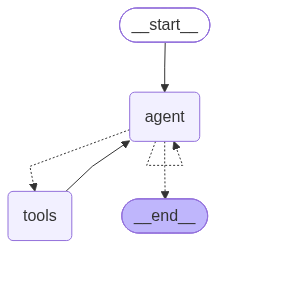

In [16]:
from IPython.display import Image
Image(app.get_graph().draw_mermaid_png())

## 9. Run-1: Policy Search for Excessive Security Deposit Query

A retrieval-focused task:
- The agent should validate scope with `parse_query`
- Then ground its answer in the policy knowledge base via `policy_search_tool`.
- Watch the 👀 Observations — they are real MCP tool outputs, not model text.


In [17]:
answer_1 = await run_legal_agent(
    """I am planning to rent an apartment in New York City under a three-year lease. The landlord is demanding a security deposit equal to 12 months of rent. This seems excessive to me. Is this legal?"""
)

🧠 Thought:I need to validate the user's query to ensure it pertains to tenant/landlord law in New York and to identify the key legal issues involved, specifically regarding security deposits. 

Action: parse_query
Action Input: I am planning to rent an apartment in New York City under a three-year lease. The landlord is demanding a security deposit equal to 12 months of rent. This seems excessive to me. Is this legal?
⚡ MCP call -> parse_query({"query": "I am planning to rent an apartment in New York City under a three-year lease. The landlord is demanding a security deposit equal to 12 months of rent. This seems excessive to me. Is this le ... [206 chars total])

👀 Observation [parse_query]:
[{'type': 'text', 'text': 'Parsed Tenant Law Query\n-----------------------\nScope Validation: Tenant / Landlord Law CONFIRMED\nUser Intent: Security Deposit Dispute\nJurisdiction: New York, US (fixed for this demo)\nProperty Type: Apartment\nTenancy Type: Fixed-Term Lease\nKey Legal Issues:\n- Se

### Expected Output — Run-1

**Correct tool-call sequence:**

| Step | Tool | Purpose |
|------|------|---------|
| 1 | `parse_query` | Validate scope; tag intent as *Security Deposit Dispute*, tenancy as *Fixed-Term Lease* |
| 2 | `policy_search_tool` | Retrieve the HSTPA 2019 one-month security deposit cap from the knowledge base |

**What each Observation should contain:**

- `parse_query` → `Scope: CONFIRMED`, `Intent: Security Deposit Dispute`, `Tenancy Type: Fixed-Term Lease`
- `policy_search_tool` → excerpts mentioning the HSTPA 2019 one-month cap and RPL § 227-e

**What the Final Answer must include:**
- Explicit ruling: a 12-month deposit is **illegal** under New York law
- Reference to the one-month cap (HSTPA 2019 / RPL § 227-e if present in context)
- Practical next steps: written notice to landlord, DHCR complaint option, legal aid referral
- No hallucinated statute numbers beyond what was retrieved

**Expected evaluation score ranges:**

| Metric | Expected Range | Why |
|--------|---------------|-----|
| Task Completion | 6/6 = 1.00 | Clean retrieval run; all checks pass |
| Groundedness | 0.80 – 0.95 | Most claims backed by policy excerpts; minor gap if agent adds procedural advice beyond the context |
| Faithfulness | 0.85 – 1.00 | Low distortion risk for a straightforward one-rule retrieval |
| Answer Relevance | 0.90 – 1.00 | Question is a direct yes/no + next steps; answer should address both |
| Citation Precision | 0.60 – 0.80 | Agent may cite "HSTPA 2019" generically without the exact RPL section number from the context |


## 10. Run-2: Case & Policy Analysis for Non-Payment and Unauthorized Subletting

A multi-source task:
- The agent should combine `policy_search_tool` and `cases_search_tool` (optionally `tavily_web_search_tool` for recent decisions) to produce a lawful step-by-step eviction plan — including what the landlord may NOT do (self-help eviction).


In [18]:
answer_2 = await run_legal_agent(
    """I'm a landlord in New York City. My tenant in a market-rate apartment has not paid rent for 3 months and is subletting the entire unit on Airbnb without my permission.

Here's the relevant clause from our 1-year lease agreement:

"Rent is due on the 1st of each month. Late fee of $100 after the 5th. Subletting or assignment of the lease is strictly prohibited without prior written consent of the Landlord. In the event of any default by Tenant, including non-payment of rent, Landlord may terminate the lease immediately and re-enter the premises."

As the landlord, can I evict the tenant quickly? Am I allowed to change the locks or remove their belongings if they don't leave voluntarily? What exact legal steps must I follow to regain possession?"""
)

🧠 Thought:I need to validate the query to ensure it pertains to tenant/landlord law and identify the key legal issues involved, such as eviction procedures and tenant rights regarding subletting without permission. 

Action: parse_query
Action Input: I'm a landlord in New York City. My tenant in a market-rate apartment has not paid rent for 3 months and is subletting the entire unit on Airbnb without my permission. Here's the relevant clause from our 1-year lease agreement: "Rent is due on the 1st of each month. Late fee of $100 after the 5th. Subletting or assignment of the lease is strictly prohibited without prior written consent of the Landlord. In the event of any default by Tenant, including non-payment of rent, Landlord may terminate the lease immediately and re-enter the premises." As the landlord, can I evict the tenant quickly? Am I allowed to change the locks or remove their belongings if they don't leave voluntarily? What exact legal steps must I follow to regain possession

### Expected Output — Run-2

**Correct tool-call sequence:**

| Step | Tool | Purpose |
|------|------|---------|
| 1 | `parse_query` | Validate scope; tag *Eviction*, *Unauthorized subletting*, *Notice requirements* |
| 2 | `policy_search_tool` | Retrieve formal eviction procedure and self-help prohibition |
| 3 | `cases_search_tool` | Retrieve case precedents on non-payment + lease-violation eviction |
| *(opt.)* | `tavily_web_search_tool` | Search for recent NYC housing-court decisions if the above leave gaps |

**What each Observation should contain:**

- `parse_query` → `Scope: CONFIRMED`, `Intent: Eviction Defense / Eviction Process`,
  Issues: *Notice requirements*, *Unauthorized subletting*, *Rent payment obligations*
- `policy_search_tool` → written-notice requirements, self-help eviction prohibition, marshal-only re-entry rule
- `cases_search_tool` → precedents covering non-payment eviction timelines or Airbnb subletting violations

**What the Final Answer must include:**
- Step-by-step legal eviction process (written notice → Housing Court petition → court judgment → city marshal)
- **Explicit statement** that changing locks or removing belongings without a court order is **illegal** self-help eviction and exposes the landlord to liability
- Two separate grounds cited: non-payment AND lease violation (subletting)
- No mixing up criminal and civil processes

**Expected evaluation score ranges:**

| Metric | Expected Range | Why |
|--------|---------------|-----|
| Task Completion | 6/6 = 1.00 | Multi-tool run; all checks should pass |
| Groundedness | 0.78 – 0.92 | Some procedural steps (e.g. specific court filing forms) may not be in the local knowledge base |
| Faithfulness | 0.82 – 0.97 | Multi-source retrieval raises the chance of a minor paraphrase error |
| Answer Relevance | 0.85 – 1.00 | Query has three sub-questions; answer must address all three to score 1.0 |
| Citation Precision | 0.50 – 0.75 | Eviction procedure involves many statutes; agent may generalise to "NY law" rather than cite specific RPL sections |


## 11. Run-3: Legal Clause Rewriting for Draft Lease Agreement

An action task:
- After gathering evidence, the agent must call the MCP-hosted `rewrite_legal_clause` tool — passing the original clauses **plus the evidence it already retrieved** as arguments — to produce a compliant rewrite with an explanation of changes.


In [19]:
answer_3 = await run_legal_agent(
    """I drafted the following New York residential lease agreement myself. Please rewrite it so it fully complies with New York law, while remaining as landlord-protective as legally allowed, and briefly explain the required changes.

DRAFT LEASE AGREEMENT:
1. Rent is due on the 1st. Any late payment incurs a $300 late fee.
2. If rent is unpaid for 5 days, Landlord may change locks and remove Tenant's belongings.
3. Tenant waives all rights to eviction notices and court proceedings.
4. Security deposit equals two months' rent and is non-refundable.
5. Landlord may enter the apartment at any time without notice.
6. Tenant is responsible for all repairs, regardless of cost.
7. Tenant agrees not to complain to any government agency."""
)

🧠 Thought:I need to first validate the query to ensure it pertains to tenant/landlord law in New York and identify the key legal issues present in the draft lease agreement. This will help me understand the specific areas that need to be addressed for compliance with New York law.

Action: parse_query
Action Input: I drafted the following New York residential lease agreement myself. Please rewrite it so it fully complies with New York law, while remaining as landlord-protective as legally allowed, and briefly explain the required changes.
⚡ MCP call -> parse_query({"query": "I drafted the following New York residential lease agreement myself. Please rewrite it so it fully complies with New York law, while remaining as landlord-protective as legally allowed, and ... [240 chars total])

👀 Observation [parse_query]:
[{'type': 'text', 'text': 'Parsed Tenant Law Query\n-----------------------\nScope Validation: Tenant / Landlord Law CONFIRMED\nUser Intent: Lease Review / Interpretation\nJur

### Expected Output — Run-3

**Correct tool-call sequence:**

| Step | Tool | Purpose |
|------|------|---------|
| 1 | `parse_query` | Validate scope; tag *Lease Review / Interpretation*, flag late-fee cap, deposit cap, notice waiver |
| 2 | `policy_search_tool` | Retrieve HSTPA caps on late fees and deposits, 24-hour entry-notice rule |
| 3 | `cases_search_tool` | Retrieve precedents on unconscionable clauses and waiver-of-rights provisions |
| 4 | `rewrite_legal_clause` | Rewrite all 7 clauses, passing `parse_query` output + retrieved excerpts as arguments |

> **Note:** `rewrite_legal_clause` must be called **after** at least one retrieval tool, because it requires the evidence as input arguments. If the agent calls `rewrite_legal_clause` before retrieving context, the rewrite will be ungrounded.

**What the Final Answer must include — all 7 clauses:**

| Original Clause | Required Fix |
|----------------|-------------|
| 1. `$300` late fee | Cap at the legally permissible amount (typically `$50` or less under HSTPA) |
| 2. Self-help lockout | Remove entirely; state only courts + city marshal may enforce re-entry |
| 3. Waiver of eviction notices | Invalid and unenforceable; restore statutory notice rights |
| 4. Two-month non-refundable deposit | Cap at one month; must be refundable with itemised deduction statement |
| 5. Unrestricted landlord entry | Require 24-hour written notice except in genuine emergencies |
| 6. Tenant responsible for all repairs | Limit to tenant-caused damage; habitability is landlord's responsibility |
| 7. Non-complaint clause | Remove entirely; tenant's right to report to agencies is non-waivable |

**Expected evaluation score ranges:**

| Metric | Expected Range | Why |
|--------|---------------|-----|
| Task Completion | 6/6 = 1.00 | All tools called in correct order |
| Groundedness | 0.72 – 0.90 | Rewrite involves 7 clauses; some rewrites may go slightly beyond retrieved excerpts |
| Faithfulness | 0.78 – 0.95 | Longer, structured output increases risk of minor misrepresentation |
| Answer Relevance | 0.88 – 1.00 | All 7 clauses must be addressed; partial rewrites lower this score |
| Citation Precision | 0.50 – 0.72 | Clause rewrites often cite "HSTPA" without section numbers; the model rarely reproduces exact RPL citations |


## 12. Run-4 (Scope-Guard Test): Deliberate Failure — Out-of-Scope Query

This run is **intentionally designed to fail**. It sends an employment-law question
to a tenant/landlord agent to demonstrate:

1. The scope-guard tool (`parse_query`) working correctly — it detects no housing-law
   keywords and returns `OUT_OF_SCOPE` immediately.
2. What happens downstream when the agent has **zero grounded context**: retrieval
   tools are never called, so the judge is forced to give `groundedness = 0.0` and
   `citation_precision = 0.0` regardless of how well-written the final answer is.
3. Why you need **both** evaluation layers: task-completion checks catch the missing
   retrieval step; the judge catches the zero-evidence answer. Neither alone is enough.

> **Learning point:** A high task-completion score (5/6 here) can coexist with a
> completely ungrounded answer. This is why LLM-as-a-Judge is a necessary second layer.


In [20]:
answer_4 = await run_legal_agent(
    """My employer has withheld my last three months of salary and terminated
my contract after I filed a workplace harassment complaint. What legal
protections do I have in New York, and can I sue for wrongful termination?"""
)


🧠 Thought:This query is about employment law rather than tenant/landlord (housing) law, which is outside the scope of my capabilities. I will reject this query as it does not pertain to housing law in New York. 

Action: parse_query
Action Input: My employer has withheld my last three months of salary and terminated my contract after I filed a workplace harassment complaint. What legal protections do I have in New York, and can I sue for wrongful termination?
⚡ MCP call -> parse_query({"query": "My employer has withheld my last three months of salary and terminated my contract after I filed a workplace harassment complaint. What legal protections do I have in New York, and can I su ... [229 chars total])

👀 Observation [parse_query]:
[{'type': 'text', 'text': 'OUT_OF_SCOPE:\nThis agent handles tenant and landlord (housing) law only.\nPlease ask a tenant-related question.', 'id': 'lc_a290ee50-32bd-4945-8349-fc8d7de96f9b'}]

🧾 FINAL ANSWER
This query is outside the scope of my capabiliti

### Expected Output — Run-4 (Deliberate Failure)

**Why this query is designed to fail:**

The query uses **employment-law vocabulary only** (`employer`, `salary`, `terminated`,
`harassment`, `wrongful termination`). The `parse_query` tool checks for housing-law
keywords (`tenant`, `landlord`, `lease`, `rent`, `eviction`, etc.). None match, so it
returns `OUT_OF_SCOPE` immediately.

**Expected tool-call trace:**

```
🧠 Thought: I need to validate this query...
Action: parse_query
Action Input: My employer has withheld my last three months of salary...
👀 Observation [parse_query]:
OUT_OF_SCOPE:
This agent handles tenant and landlord (housing) law only.
Please ask a tenant-related question.
🧾 FINAL ANSWER
============================================================
I'm sorry, but this agent specialises in tenant and landlord law in New York.
Your question about employment disputes and wrongful termination falls outside
my coverage. Please consult a New York employment attorney or the NYS Department
of Labor for assistance.
```

**Why each metric fails:**

| Check | Result | Reason |
|-------|--------|--------|
| `retrieval_or_search_used` | ❌ FAIL | No policy/case/web tool was called — scope guard stopped the chain |
| All other task checks | ✅ PASS | parse_query ran, a final answer was produced, no malformed turns |
| Task Completion Score | **5/6 = 0.83** | One check fails — the agent did not follow the full retrieval protocol |

| Judge Metric | Expected Score | Why |
|-------------|---------------|-----|
| Groundedness | **0.00 (FAIL)** | Guard forces this to 0 — nothing was retrieved; no claim can be grounded |
| Citation Precision | **0.00 (FAIL)** | Guard forces this to 0 — no context, no citations possible |
| Answer Relevance | **0.20 – 0.40 (FAIL)** | The OUT_OF_SCOPE redirect does not answer the user's actual legal question |
| Faithfulness | **0.40 – 0.60** | No context to be faithful to; borderline score reflects this ambiguity |

**How to resolve this type of failure:**

1. **Scope mismatch (user error):** Add a clear scope notice in the UI before the user submits — "This agent covers New York tenant and landlord law only."
2. **Multi-domain coverage:** Deploy separate specialised agents (tenant law, employment law, contract law) behind a **router agent** that classifies the query and dispatches it to the right expert.
3. **Soft rejection:** Instead of a hard OUT_OF_SCOPE message, the agent could acknowledge the query is out of scope, then suggest the appropriate resource (e.g. NYS Department of Labor website) — this would improve `answer_relevance` without expanding the agent's liability footprint.
4. **Domain expansion:** If employment law must be supported, add employment-law PDFs to the vector store and extend `parse_query` to recognise employment keywords.


## 13. Run-5: Knowledge-Base Gap and Live Web Search

A **temporal-gap** task:
- The query is about New York's Good Cause Eviction Law — a 2024 statute that post-dates the local PDF knowledge base.
- Watch the ReAct reasoning: `policy_search_tool` will return general eviction policy but nothing specific to this law.
- The agent must then recognise the gap in its evidence, reason that the topic is too recent for the local corpus, and reach for `tavily_web_search_tool` on its own — no instruction in the query tells it to do so.

In [21]:
answer_5 = await run_legal_agent(
    """I rent a non-rent-stabilized apartment in New York City. My landlord
refused to renew my lease in 2025 and handed me a 30-day notice to vacate
with no reason given. I have been a reliable tenant for three years.
Does New York's Good Cause Eviction Law protect tenants in my situation
from no-fault non-renewal, and how are courts currently applying this law
to non-rent-stabilized apartments?"""
)

🧠 Thought:I need to first validate the user's query to ensure it pertains to tenant/landlord law in New York. This will help me identify the intent, property type, tenancy type, and key legal issues involved in the situation described.

Action: parse_query
Action Input: I rent a non-rent-stabilized apartment in New York City. My landlord refused to renew my lease in 2025 and handed me a 30-day notice to vacate with no reason given. I have been a reliable tenant for three years. Does New York's Good Cause Eviction Law protect tenants in my situation from no-fault non-renewal, and how are courts currently applying this law to non-rent-stabilized apartments?
⚡ MCP call -> parse_query({"query": "I rent a non-rent-stabilized apartment in New York City. My landlord refused to renew my lease in 2025 and handed me a 30-day notice to vacate with no reason given. I have been a reliable t ... [405 chars total])

👀 Observation [parse_query]:
[{'type': 'text', 'text': 'Parsed Tenant Law Query\n----

### Expected Output — Run-5

**How the agent should reason its way to Tavily (no instruction given):**

The agent receives a natural question about a 2024 law and current court interpretations. It must work through the ReAct loop:

1. `parse_query` confirms the question is in scope and tags it as *Eviction Defense*.
2. `policy_search_tool` returns general New York eviction policy from the local PDF corpus — but nothing specific to the Good Cause Eviction Law (GCELA), because the local knowledge base pre-dates that 2024 statute.
3. The agent's Thought should recognise the gap: *'The retrieved policy does not address the Good Cause Eviction Law the user asked about. This is a recently enacted statute that may not be in the local knowledge base. I should search the web to find current information.'*
4. `tavily_web_search_tool` retrieves current web sources about the GCELA and recent Housing Court decisions — **the agent reached this tool through its own reasoning, not because the query told it to**.

**Correct tool-call sequence:**

| Step | Tool | Purpose |
|------|------|---------|
| 1 | `parse_query` | Validate scope; tag intent as *Eviction Defense / Eviction Process* |
| 2 | `policy_search_tool` | Search local corpus — returns general eviction law; no GCELA content because the PDF predates 2024 |
| 3 | `tavily_web_search_tool` | Agent recognises the evidence gap and reaches for live web search — **this should be a self-directed Thought, not prompted by the query** |
| *(opt.)* | `cases_search_tool` | Retrieve any related precedents from the local case collection |

> **How to verify Tavily was reached by reasoning:** look at the ⁠`👀 Observation [tavily_web_search_tool]`⁠ line in the run output. More importantly, read the ⁠`🧠 Thought`⁠ that precedes it — it should explicitly reason about the evidence gap from step 2, *not* just repeat what the query said. If the Thought is 'The user asked me to search the web', the agent is following an instruction, not reasoning.

**What the Tavily Observation should contain:**
- Reference to the GCELA (Part BB of the 2024–25 NY State Budget Act) and its coverage of non-rent-stabilized units
- The law's key protections: landlords must demonstrate good cause (non-payment, lease violation, substantial rehab, owner move-in) to non-renew or raise rent above the legal threshold
- Exemption categories: owner-occupied buildings with four or fewer units, units above a specified rent threshold, seasonal rentals, student housing
- Recent NYC Housing Court decisions or legal commentary on how judges are interpreting the law
- Source URLs from news outlets, legal blogs, or government sites

**What the Final Answer must include:**
- An exemption check: does the tenant's unit qualify under the GCELA (building type, rent level)?
- If covered: clear statement that no-fault non-renewal is prohibited without good cause
- If exempt: explanation of which exemption applies and what options remain
- Acknowledgement that the GCELA is recently enacted with evolving court interpretation; recommend consulting a tenant attorney
- Claims grounded in Tavily observations, not in the agent's training knowledge

**Expected evaluation score ranges:**

| Metric | Expected Range | Why |
|--------|---------------|-----|
| Task Completion | 5/6 – 6/6 = 0.83 – 1.00 | `retrieval_or_search_used` passes if Tavily fires; inspect the transcript to confirm Tavily — not just policy search — appears in the observations |
| Groundedness | 0.60 – 0.82 | Tavily returns web snippets of varying authority; some claims may go slightly beyond the retrieved text |
| Faithfulness | 0.72 – 0.92 | Lower ceiling than Run-1; web sources on a new law can conflict or be incomplete |
| Answer Relevance | 0.85 – 1.00 | A focused answer addressing the exemption check and court-interpretation caveat should score high |
| Citation Precision | 0.50 – 0.75 | Agent may name the law without citing the specific budget-act section or an individual case name |

> **Key learning point:** This run illustrates two things. First, static knowledge bases have a **temporal cutoff** — `tavily_web_search_tool` keeps the agent current when the law evolves faster than the corpus. Second, and more importantly, a well-designed ReAct agent should **reason its way to the right tool** — it reads the evidence it gets, recognises when that evidence is insufficient for the specific question, and decides to search further. That self-directed reasoning is what separates a genuinely intelligent agent from one that just follows scripted instructions.

## 14. Evaluation — Task Completion Metrics + LLM-as-a-Judge **[Optional Section]**

Two complementary evaluation layers, matching the session's evaluation objective:

1. **Pre-defined task-completion metric** — deterministic, code-level checks on the run transcript: Did the agent produce a final answer? Did it follow the required tool protocol? Did every tool call succeed? Cheap, objective, and reproducible.
2. **LLM-as-a-Judge** — a rubric-scored qualitative review of the final answer on **groundedness**, **faithfulness**, and **answer relevance**, judged against the evidence the agent *actually retrieved* (its tool observations).

> ⚠️ **Judge caveat:** if no context was retrieved, groundedness is forced to 0 — an answer cannot be grounded in evidence that does not exist. The judge runs on **GPT-4o** (a stronger model than the `gpt-4o-mini` agent) to reduce self-preference bias and produce more calibrated scores.


### 14.1 Capture a Full Run (answer + retrieved evidence + transcript)

In [22]:
async def run_and_capture(query: str):
    """
    Run the agent to completion (silently) and return:
      - final_answer: the last AIMessage without tool calls (malformed
        ReAct turns are excluded — they are retries, not answers)
      - context: the list of REAL tool observations (retrieved evidence);
        parse-error system responses are excluded — they are not evidence
      - messages: the full transcript, for the task-completion checks
    """
    final_messages = []
    async for step in app.astream(
        {"messages": [HumanMessage(content=query)], "step_count": 0},
        stream_mode="values",
        config={"recursion_limit": 50},
    ):
        final_messages = step.get("messages", final_messages)

    final_answer = ""
    context = []
    for msg in final_messages:
        if isinstance(msg, ToolMessage):
            if not msg.content.startswith(("Input parse error", "Tool error", "Unknown tool")):
                context.append(f"[{msg.name}]\n{msg.content}")
        elif (isinstance(msg, AIMessage) and not msg.tool_calls
              and not msg.additional_kwargs.get("malformed_react")):
            final_answer = msg.content.strip()

    return final_answer, context, final_messages


### 14.2 Pre-Defined Task Completion Metric (deterministic)

In [23]:
def task_completion_metric(final_answer: str, messages: List[BaseMessage]) -> float:
    """
    Score task completion with objective, pre-defined checks over the
    transcript. Returns the fraction of checks passed.
    """
    tool_calls = [tc["name"] for m in messages
                  if isinstance(m, AIMessage) and m.tool_calls
                  for tc in m.tool_calls]
    observations = [m for m in messages if isinstance(m, ToolMessage)]

    checks = {
        "final_answer_produced": bool(final_answer.strip()),
        "parse_query_called_first": bool(tool_calls) and tool_calls[0] == "parse_query",
        "retrieval_or_search_used": any(
            t in {"policy_search_tool", "cases_search_tool", "tavily_web_search_tool"}
            for t in tool_calls),
        "evidence_captured": len(observations) > 0,
        # Covers real tool failures AND unparseable Action Inputs (which never
        # reach the MCP server at all).
        "all_tool_calls_succeeded": bool(observations) and all(
            not m.content.startswith(("Tool error", "Unknown tool", "Input parse error"))
            for m in observations),
        # Falsifiable format check: did every ReAct turn parse cleanly?
        "no_malformed_react_turns": not any(
            isinstance(m, AIMessage) and m.additional_kwargs.get("malformed_react")
            for m in messages),
    }

    print("TASK COMPLETION CHECKS")
    print("-" * 60)
    for name, passed in checks.items():
        print(f"  {'✅' if passed else '❌'}  {name}")
    score = sum(checks.values()) / len(checks)
    print("-" * 60)
    print(f"Task Completion Score: {score:.2f}  "
          f"({sum(checks.values())}/{len(checks)} checks passed)\n")
    return score


### 14.3 LLM-as-a-Judge (groundedness, faithfulness, relevance)

In [24]:
JUDGE_PROMPT = """You are a strict, impartial evaluator of a legal assistant's answer.
Score the answer on FOUR metrics, each from 0.0 (worst) to 1.0 (best).
Reserve 1.0 only for genuinely exceptional answers; most competent answers
should score in the 0.7-0.9 range.

1. groundedness      - Are the factual/legal claims in the ANSWER supported by the
   RETRIEVED CONTEXT? Penalise for any claim that goes beyond or cannot be
   verified in the context. Score 0.0 if no context was retrieved.

2. faithfulness      - Does the ANSWER avoid contradicting or misrepresenting the
   RETRIEVED CONTEXT? Any distortion, paraphrase that changes meaning, or
   omission of a material caveat lowers this score.

3. answer_relevance  - Does the ANSWER directly address what the USER QUESTION
   asked? Penalise for off-topic elaboration, unanswered sub-questions, or
   a response that is technically accurate but unhelpfully generic.

4. citation_precision - Does the ANSWER reference specific statutes, section
   numbers, case names, or other precise identifiers that appear in the
   RETRIEVED CONTEXT? Generic phrases such as "under New York law" or
   "according to the statute" without citing the specific provision found
   in the context should score below 0.6.

Scoring guidance:
  1.0     Perfect: every claim verified in context; specific citations used; no gaps.
  0.8-0.9 Strong: mostly grounded; at most one minor unsupported or generalised claim.
  0.6-0.7 Adequate: correct direction but generalises beyond or misses key nuances.
  < 0.6   Weak: significant unsupported claims, contradictions, or off-topic content.

USER QUESTION:
{question}

RETRIEVED CONTEXT (evidence the agent actually retrieved):
{context}

ANSWER:
{answer}

Respond with ONLY a valid JSON object, no markdown, no backticks, in exactly
this shape:
{{
  "groundedness":       {{"score": <float>, "reason": "<one sentence identifying the strongest evidence or the main gap>"}},
  "faithfulness":       {{"score": <float>, "reason": "<one sentence>"}},
  "answer_relevance":   {{"score": <float>, "reason": "<one sentence>"}},
  "citation_precision": {{"score": <float>, "reason": "<one sentence citing what was or was not specifically referenced>"}}
}}"""


judge_llm = ChatOpenAI(model_name="gpt-4o", temperature=0.0)


def judge_answer(question: str, answer: str, context: list, threshold: float = 0.7):
    """LLM-as-a-judge scoring with a hard guard: no retrieved context means
    groundedness and citation_precision are 0 by definition."""
    prompt = JUDGE_PROMPT.format(
        question=question.strip(),
        context="\n\n".join(context) if context else "(no context retrieved)",
        answer=answer.strip() or "(empty answer)",
    )

    raw = judge_llm.invoke(prompt).content.strip()
    raw = re.sub(r"^```(?:json)?|```$", "", raw, flags=re.MULTILINE).strip()

    try:
        scores = json.loads(raw)
    except json.JSONDecodeError:
        print("Could not parse judge output as JSON. Raw response:\n", raw)
        return None

    # GUARD: an answer cannot be grounded or cited from evidence never retrieved.
    if not context:
        scores["groundedness"] = {
            "score": 0.0,
            "reason": "No context was retrieved, so no claim can be grounded.",
        }
        scores["citation_precision"] = {
            "score": 0.0,
            "reason": "No context was retrieved, so no citations are possible.",
        }

    print("=" * 60)
    print("LLM-AS-A-JUDGE EVALUATION")
    print("=" * 60)
    all_pass = True
    for metric in ["groundedness", "faithfulness", "answer_relevance", "citation_precision"]:
        entry = scores.get(metric, {})
        score = float(entry.get("score", 0.0))
        passed = score >= threshold
        all_pass = all_pass and passed
        print(f"\n{metric.replace('_', ' ').title()}")
        print(f"  Score : {score:.2f}  ({'PASSED' if passed else 'FAILED'}, threshold {threshold})")
        print(f"  Reason: {entry.get('reason', '')}")
    print("\n" + "=" * 60)
    print(f"Overall: {'ALL METRICS PASSED' if all_pass else 'SOME METRICS FAILED'}")
    print("=" * 60)
    return scores


### 14.4 Run the Evaluation Pipeline

> **Before running this cell:** make sure you have executed Cells 14.1–14.3 above. Those cells **define functions only** — no agent calls happen until this cell runs.

This cell evaluates the agent on **four test queries** of increasing scope:

- **Query A** (retrieval-focused) — security deposit limit; same scenario as Run-1 so you can compare the live evaluation trace against the step-by-step trace above.
- **Query B** (multi-issue) — eviction + habitability dispute; the agent must reason across overlapping legal issues, which typically yields lower scores than Query A.
- **Query C** (out-of-scope, **deliberately failing**) — an employment-law query sent to a tenant/landlord agent. `parse_query` returns `OUT_OF_SCOPE`, no retrieval tools are called, and the judge is forced to give `groundedness = 0.0` and `citation_precision = 0.0`. Compare its scores against Queries A and B to see what a genuine evaluation failure looks like.
- **Query D** (live web search) — a question about a 2024 statute not in the local PDFs, requiring `tavily_web_search_tool` to answer. Compare its groundedness and citation-precision scores against Queries A and B to see the difference between curated-retrieval answers and web-search answers.

> **What to look for:** Query C shows that task-completion and LLM-as-a-Judge catch *different kinds* of failure. Query D shows how web-search answers score differently from knowledge-base-retrieval answers — useful for deciding when to invest in curating a local corpus.

In [25]:
EVAL_QUERIES = [
    (
        "Query A — Security Deposit (retrieval-focused)",
        """I am planning to rent an apartment in New York City. The landlord is demanding a security deposit equal to 12 months of rent. Is this legal?"""
    ),
    (
        "Query B — Eviction + Habitability (multi-issue)",
        """My tenant stopped paying rent two months ago. They claim they are withholding rent because the radiator in their apartment has not worked for six weeks. Can I evict them, and what heating obligations do I have under New York law before I can file?"""
    ),
    (
        "Query C — Employment Law (out-of-scope, DESIGNED TO FAIL)",
        """My employer has withheld my last three months of salary and terminated my contract after I filed a workplace harassment complaint. What legal protections do I have in New York, and can I sue for wrongful termination?"""
    ),
    (
        "Query D \u2014 Good Cause Eviction (Tavily web search)",
        """I rent a non-rent-stabilized apartment in New York City. My landlord
refused to renew my lease in 2025 and handed me a 30-day notice to vacate
with no reason given. Does New York's Good Cause Eviction Law protect tenants
in my situation from no-fault non-renewal, and how are courts currently
applying this law to non-rent-stabilized apartments?"""
    ),
]

for label, query in EVAL_QUERIES:
    print(f"\n{'=' * 60}")
    print(f"EVALUATING: {label}")
    print(f"{'=' * 60}\n")

    eval_answer, eval_context, eval_messages = await run_and_capture(query)

    print("ANSWER:\n", eval_answer, "\n")
    print(f"Captured {len(eval_context)} context passage(s) from REAL tool observations.\n")

    tc_score = task_completion_metric(eval_answer, eval_messages)
    judge_scores = judge_answer(query, eval_answer, eval_context, threshold=0.7)



EVALUATING: Query A — Security Deposit (retrieval-focused)

ANSWER:
 In New York City, it is illegal for a landlord to demand a security deposit equal to 12 months of rent. The law caps security deposits at one month's rent. 

Captured 2 context passage(s) from REAL tool observations.

TASK COMPLETION CHECKS
------------------------------------------------------------
  ✅  final_answer_produced
  ✅  parse_query_called_first
  ✅  retrieval_or_search_used
  ✅  evidence_captured
  ✅  all_tool_calls_succeeded
  ✅  no_malformed_react_turns
------------------------------------------------------------
Task Completion Score: 1.00  (6/6 checks passed)

LLM-AS-A-JUDGE EVALUATION

Groundedness
  Score : 1.00  (PASSED, threshold 0.7)
  Reason: The answer is fully supported by the retrieved context, which states that security deposits are capped at one month's rent.

Faithfulness
  Score : 1.00  (PASSED, threshold 0.7)
  Reason: The answer accurately reflects the retrieved context without any dist

## 15. Cleanup — Stop the MCP Server

In [26]:
mcp_server_process.terminate()
mcp_server_process.wait()
server_log.close()
print("MCP server stopped.")


MCP server stopped.


## 16. Conclusion and Recommendations

### Conclusion
LexAgent handles tenant–landlord queries by combining query parsing, policy and case retrieval, web search, and clause rewriting within an explicit ReAct loop, with **all five tools served through a standalone MCP server over streamable HTTP** — every observation in the traces above is a genuine client→server tool round trip. Runs are evaluated on two layers: **pre-defined task-completion checks** over the transcript and an **LLM-as-a-Judge** rubric scored against the evidence the agent actually retrieved.

### Recommendations
1. **Expand the Legal Knowledge Base** — Include more recent case law, city regulations, and tenant-protection guidelines to improve coverage and accuracy.
2. **Multi-Jurisdiction Support** — Extend beyond New York by loading jurisdiction-specific policies and case law, potentially as additional MCP servers per jurisdiction (and replace `parse_query`'s fixed jurisdiction with real detection).
3. **Stronger Evaluation** — The judge already uses **GPT-4o** (separate from the `gpt-4o-mini` agent) to reduce self-preference bias. Further improvements: add a golden test set of queries with expected tool paths and track evaluation scores across runs to detect regressions.
4. **Conversational Interaction Support** — Extend to a multi-turn chat format with memory for follow-up questions.
5. **Production MCP Hosting** — Move the MCP server off `127.0.0.1` onto a persistent, authenticated deployment (API-key or OAuth) if this moves beyond a notebook demo.
